# UK Turnout Analysis Project

## NB05: Predictive modelling

This notebook asks a different question from the regression analysis in NB04.

Rather than estimating and interpreting conditional associations, the aim here is
to assess how accurately constituency turnout can be predicted for observations
not used to fit the model.

Several models are compared using the same cross-validation splits. Linear
regression provides a baseline, while regularised linear models and tree-based
methods allow for correlated predictors and, in the latter case, nonlinear
relationships and interactions.

Performance is evaluated out of sample using RMSE, MAE and R^2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    RepeatedKFold,
    cross_validate,
    GridSearchCV,
    KFold,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.compose import ColumnTransformer


In [2]:
data = pd.read_csv("../data/processed/analysis_data.csv")

assert len(data) == 575
assert data["constituency_code"].is_unique
assert data.notna().all().all()

data["log_population_density"] = np.log(
    data["population_density"]
)

In [3]:
predictive_features = [
    "level4_plus_pct",
    "age_18_34_pct",
    "age_65_plus_pct",
    "owner_occupied_pct",
    "social_rented_pct",
    "unemployment_rate",
    "log_population_density"
]

X = data[predictive_features]
y = data["turnout_pct"]

#### Predictor set

All seven candidate predictors are retained for predictive modelling.

The 18–34 age measure was removed from the preferred explanatory regression
because it added little independent information and contributed to
multicollinearity. Prediction has a different objective: coefficient stability
and individual statistical significance are not themselves criteria for
excluding a variable.

Regularised and tree-based models can determine whether the additional age
information improves out-of-sample predictions.

### 1. Cross-Validation

In [4]:
cv = RepeatedKFold(
    n_splits=10,
    n_repeats=5,
    random_state=42
)

In [5]:
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

#### Linear regression baseline

Ordinary least squares provides the baseline predictive model. Unlike the
explanatory analysis, performance is assessed entirely on constituencies held
out from each model fit.

In [6]:
linear_model = LinearRegression()

linear_scores = cross_validate(
    linear_model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [7]:
linear_results = pd.Series({
    "RMSE": -linear_scores["test_rmse"].mean(),
    "MAE": -linear_scores["test_mae"].mean(),
    "R²": linear_scores["test_r2"].mean()
})

linear_results

RMSE    3.093503
MAE     2.358713
R²      0.793275
dtype: float64

In [8]:
pd.DataFrame({
    "RMSE": -linear_scores["test_rmse"],
    "MAE": -linear_scores["test_mae"],
    "R²": linear_scores["test_r2"]
}).describe()

,RMSE,MAE,R²
count,50.000000,50.000000,50.000000
mean,3.093503,2.358713,0.793275
std,0.373994,0.246297,0.056652
min,2.365995,1.826155,0.594971
25%,2.795980,2.194680,0.758773
50%,3.137006,2.393571,0.803976
75%,3.278556,2.525973,0.833711
max,4.009990,2.979493,0.884310


The linear model is already a fairly strong predictive baseline. Across repeated
10-fold cross-validation, it explains around 79% of the variation in turnout in
held-out constituencies.

Its average prediction error is around 3.1 percentage points using RMSE, or
2.4 percentage points using MAE. This is only slightly weaker than the model's
fit to the full dataset, suggesting that the relationships identified in NB04
generalise reasonably well within the 2024 constituency sample.

Performance does vary across folds, however, so the comparison with more complex
models should be based on the full distribution of cross-validation results
rather than a single train/test split.

### 2. Regularised linear models

The predictors are fairly strongly correlated, particularly the age and housing
variables. Ridge and LASSO regression are therefore compared with ordinary least
squares.

Both models penalise large coefficients. Ridge retains all predictors but shrinks
them towards zero, while LASSO can set coefficients exactly to zero if they add
little predictive information.

The penalty strength is tuned within each cross-validation training sample, so
the held-out constituencies are not used to choose the model.

In [9]:
inner_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [10]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={
        "model__alpha": np.logspace(-4, 4, 100)
    },
    cv=inner_cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

ridge_scores = cross_validate(
    ridge_search,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

In [11]:
ridge_results = pd.Series({
    "RMSE": -ridge_scores["test_rmse"].mean(),
    "MAE": -ridge_scores["test_mae"].mean(),
    "R²": ridge_scores["test_r2"].mean()
})

ridge_results

RMSE    3.093825
MAE     2.361266
R²      0.793291
dtype: float64

In [12]:
ridge_alphas = [
    estimator.best_params_["model__alpha"]
    for estimator in ridge_scores["estimator"]
]

pd.Series(ridge_alphas).describe()

count    50.000000
mean      5.711931
std       3.177580
min       0.000100
25%       3.351603
50%       5.359811
75%       7.054802
max      14.849683
dtype: float64

In [13]:
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000))
])

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={
        "model__alpha": np.logspace(-4, 1, 100)
    },
    cv=inner_cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

lasso_scores = cross_validate(
    lasso_search,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

In [14]:
lasso_results = pd.Series({
    "RMSE": -lasso_scores["test_rmse"].mean(),
    "MAE": -lasso_scores["test_mae"].mean(),
    "R²": lasso_scores["test_r2"].mean()
})

lasso_results

RMSE    3.091682
MAE     2.361250
R²      0.793572
dtype: float64

In [15]:
lasso_alphas = [
    estimator.best_params_["model__alpha"]
    for estimator in lasso_scores["estimator"]
]

pd.Series(lasso_alphas).describe()

count    50.000000
mean      0.033218
std       0.018905
min       0.000100
25%       0.026561
50%       0.033516
75%       0.047508
max       0.067342
dtype: float64

In [16]:
linear_model_results = pd.DataFrame({
    "Linear regression": linear_results,
    "Ridge": ridge_results,
    "LASSO": lasso_results
}).T

linear_model_results

,RMSE,MAE,R²
Linear regression,3.093503,2.358713,0.793275
Ridge,3.093825,2.361266,0.793291
LASSO,3.091682,2.361250,0.793572


In [17]:
cv_comparison = pd.DataFrame({
    "Linear regression": -linear_scores["test_rmse"],
    "Ridge": -ridge_scores["test_rmse"],
    "LASSO": -lasso_scores["test_rmse"]
})

cv_comparison.describe()

,Linear regression,Ridge,LASSO
count,50.000000,50.000000,50.000000
mean,3.093503,3.093825,3.091682
std,0.373994,0.374504,0.372802
min,2.365995,2.357176,2.365863
25%,2.795980,2.798449,2.795672
50%,3.137006,3.133062,3.114458
75%,3.278556,3.267232,3.281093
max,4.009990,4.009593,4.013264


In [18]:
rmse_differences = pd.DataFrame({
    "Ridge minus OLS": (
        -ridge_scores["test_rmse"]
        + linear_scores["test_rmse"]
    ),
    "LASSO minus OLS": (
        -lasso_scores["test_rmse"]
        + linear_scores["test_rmse"]
    )
})

rmse_differences.describe()

,Ridge minus OLS,LASSO minus OLS
count,50.000000,50.000000
mean,0.000322,-0.001821
std,0.014965,0.018072
min,-0.025716,-0.055382
25%,-0.007721,-0.002995
50%,0.000207,0.000903
75%,0.004575,0.008724
max,0.055738,0.029791


In [19]:
lasso_coefficients = pd.DataFrame([
    estimator.best_estimator_
    .named_steps["model"]
    .coef_
    for estimator in lasso_scores["estimator"]
], columns=predictive_features)

(lasso_coefficients == 0).sum()

level4_plus_pct            0
age_18_34_pct             40
age_65_plus_pct            0
owner_occupied_pct         0
social_rented_pct          0
unemployment_rate          0
log_population_density     0
dtype: int64

Regularisation makes almost no difference to predictive performance.

Ridge regression performs effectively identically to ordinary least squares.
LASSO produces the lowest average RMSE and highest R-squared of the three models,
but the difference is extremely small: its RMSE is only around 0.002 percentage
points lower than the OLS baseline.

This is useful in itself. Multicollinearity was important when interpreting the
individual regression coefficients in NB04, but it does not appear to create a
meaningful problem for prediction. The information contained in the correlated
predictors can already be used effectively by a simple linear model, and
regularisation adds very little out of sample.

### 3. Tree-based models

The linear models all perform almost identically, but still impose a broadly linear relationship between the predictors and turnout.

Random forest and gradient boosting models are therefore used to test whether allowing nonlinear relationships and interactions improves out-of-sample prediction. Their hyperparameters are tuned within each training fold using the same outer cross-validation splits as the linear models.

In [20]:
random_forest = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    n_jobs=1
)

rf_search = RandomizedSearchCV(
    estimator=random_forest,
    param_distributions={
        "max_depth": [None, 4, 6, 8, 12],
        "min_samples_split": [2, 5, 10, 20],
        "min_samples_leaf": [1, 2, 4, 8],
        "max_features": ["sqrt", 0.5, 0.75, 1.0]
    },
    n_iter=12,
    cv=inner_cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1
)

rf_scores = cross_validate(
    rf_search,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

rf_results = pd.Series({
    "RMSE": -rf_scores["test_rmse"].mean(),
    "MAE": -rf_scores["test_mae"].mean(),
    "R²": rf_scores["test_r2"].mean()
})

rf_results

RMSE    3.144900
MAE     2.418537
R²      0.784820
dtype: float64

In [21]:
gradient_boosting = GradientBoostingRegressor(
    random_state=42
)

gb_search = RandomizedSearchCV(
    estimator=gradient_boosting,
    param_distributions={
        "n_estimators": [50, 100, 150, 200, 300],
        "learning_rate": [0.02, 0.03, 0.05, 0.075, 0.1],
        "max_depth": [1, 2, 3],
        "min_samples_leaf": [2, 4, 8, 12],
        "subsample": [0.7, 0.85, 1.0]
    },
    n_iter=12,
    cv=inner_cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1
)

gb_scores = cross_validate(
    gb_search,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

gb_results = pd.Series({
    "RMSE": -gb_scores["test_rmse"].mean(),
    "MAE": -gb_scores["test_mae"].mean(),
    "R²": gb_scores["test_r2"].mean()
})

gb_results

RMSE    3.049720
MAE     2.348461
R²      0.796730
dtype: float64

In [22]:
model_comparison = pd.DataFrame({
    "Linear regression": linear_results,
    "Ridge": ridge_results,
    "LASSO": lasso_results,
    "Random forest": rf_results,
    "Gradient boosting": gb_results
}).T

model_comparison.sort_values("RMSE")

,RMSE,MAE,R²
Gradient boosting,3.049720,2.348461,0.796730
LASSO,3.091682,2.361250,0.793572
Linear regression,3.093503,2.358713,0.793275
Ridge,3.093825,2.361266,0.793291
Random forest,3.144900,2.418537,0.784820


### Results

Allowing for nonlinear relationships and interactions produces mixed results.

Random forest performs worse than all three linear models, with a higher RMSE and MAE and a lower out-of-sample R^2. Gradient boosting performs best, but the improvement is fairly small. Its average RMSE falls from around 3.09pp under OLS to 3.05, while R^2 rises from around 0.793 to 0.797.

This suggests that there is some additional nonlinear structure in the data,
but not very much. Most of the useful information in these predictors appears
to be captured by the linear model already. A more flexible model can improve
prediction slightly, but at the cost of substantially greater complexity and
computation.

In [23]:
tree_rmse_comparison = pd.DataFrame({
    "Linear regression": -linear_scores["test_rmse"],
    "Random forest": -rf_scores["test_rmse"],
    "Gradient boosting": -gb_scores["test_rmse"]
})

tree_rmse_comparison.describe()

,Linear regression,Random forest,Gradient boosting
count,50.000000,50.000000,50.000000
mean,3.093503,3.144900,3.049720
std,0.373994,0.419661,0.412904
min,2.365995,2.327415,2.303429
25%,2.795980,2.838084,2.788150
50%,3.137006,3.135100,3.023614
75%,3.278556,3.393933,3.309517
max,4.009990,4.143585,4.026452


In [24]:
tree_rmse_differences = pd.DataFrame({
    "Random forest minus OLS": (
        -rf_scores["test_rmse"]
        + linear_scores["test_rmse"]
    ),
    "Gradient boosting minus OLS": (
        -gb_scores["test_rmse"]
        + linear_scores["test_rmse"]
    )
})

tree_rmse_differences.describe()

,Random forest minus OLS,Gradient boosting minus OLS
count,50.000000,50.000000
mean,0.051397,-0.043783
std,0.235519,0.197042
min,-0.463866,-0.484242
25%,-0.062178,-0.180295
50%,0.035682,-0.000243
75%,0.251539,0.090132
max,0.522913,0.412934


In [25]:
print(
    "Gradient boosting beats OLS in",
    (tree_rmse_differences["Gradient boosting minus OLS"] < 0).sum(),
    "of 50 folds"
)

print(
    "Random forest beats OLS in",
    (tree_rmse_differences["Random forest minus OLS"] < 0).sum(),
    "of 50 folds"
)

Gradient boosting beats OLS in 25 of 50 folds
Random forest beats OLS in 24 of 50 folds


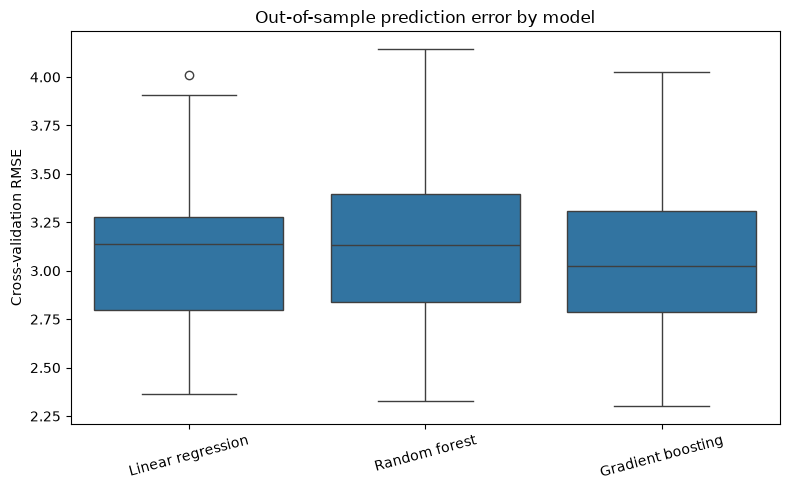

In [26]:
rmse_long = tree_rmse_comparison.melt(
    var_name="Model",
    value_name="RMSE"
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=rmse_long,
    x="Model",
    y="RMSE"
)

plt.ylabel("Cross-validation RMSE")
plt.xlabel("")
plt.title("Out-of-sample prediction error by model")

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "../figures/model_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Comparing linear and tree-based models

Gradient boosting gives the lowest average prediction error, although the improvement over the linear model is small. Its RMSE is around 0.04pp lower on average, but this advantage is not especially consistent across the cross-validation folds: gradient boosting beats ordinary least squares in only 25 of the 50 comparisons, and the median difference in RMSE is effectively zero.

Random forest performs slightly worse on average and also shows no consistent advantage over the linear model.

This suggests that allowing for nonlinearities and interactions adds relatively little predictive information. Gradient boosting can improve predictions in some parts of the sample, but the simpler linear model performs almost as well overall and is considerably easier to interpret. Most of the predictive relationship between these constituency characteristics and turnout therefore appears to be captured by the linear structure already.

In [27]:
permutation_results = []

for (_, test_idx), fitted_search in zip(
    cv.split(X, y),
    gb_scores["estimator"]
):
    fitted_model = fitted_search.best_estimator_

    importance = permutation_importance(
        fitted_model,
        X.iloc[test_idx],
        y.iloc[test_idx],
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    permutation_results.append(
        importance.importances_mean
    )

permutation_results = np.array(permutation_results)

permutation_summary = pd.DataFrame({
    "feature": predictive_features,
    "importance_mean": permutation_results.mean(axis=0),
    "importance_std": permutation_results.std(axis=0)
}).sort_values(
    "importance_mean",
    ascending=False
)

permutation_summary

,feature,importance_mean,importance_std
0,level4_plus_pct,2.823040,0.469036
5,unemployment_rate,1.618187,0.427948
4,social_rented_pct,0.714315,0.222918
3,owner_occupied_pct,0.276923,0.233265
1,age_18_34_pct,0.215331,0.085282
2,age_65_plus_pct,0.042481,0.060441
6,log_population_density,0.015892,0.030988


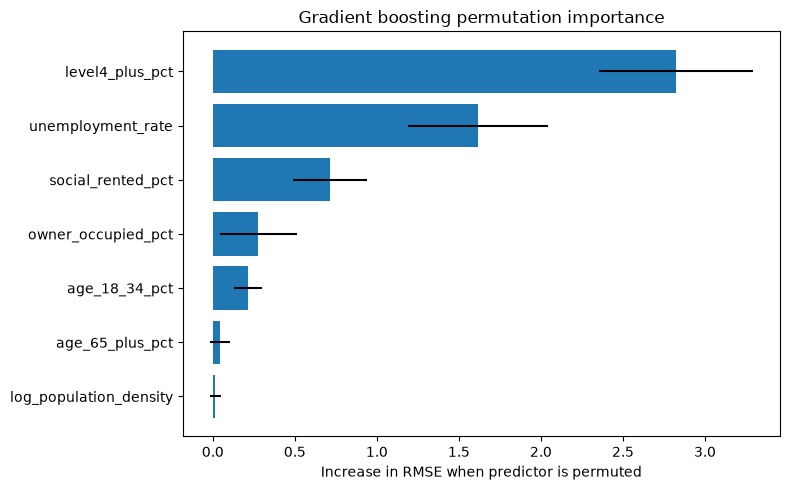

In [28]:
plot_importance = permutation_summary.sort_values(
    "importance_mean"
)

plt.figure(figsize=(8, 5))

plt.barh(
    plot_importance["feature"],
    plot_importance["importance_mean"],
    xerr=plot_importance["importance_std"]
)

plt.xlabel("Increase in RMSE when predictor is permuted")
plt.ylabel("")
plt.title("Gradient boosting permutation importance")

plt.tight_layout()

plt.savefig(
    "../figures/gradient_boosting_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Which variables matter for prediction?

Permutation importance shows that the gradient boosting model relies most heavily
on educational attainment and unemployment. Shuffling either variable in the
held-out data causes a large increase in prediction error, with education having
by far the largest effect.

Social renting also contributes meaningfully, while owner occupation and the
18–34 population share add smaller amounts of predictive information. By
contrast, the model makes very little use of the 65+ population share or
population density once the other predictors are available.

This differs slightly from the explanatory regression in NB04, where both age
and population density remained statistically significant. The two results are
not contradictory. A variable can have a detectable conditional association
with turnout without adding much unique predictive information, particularly
when several predictors are strongly correlated.

Taken together, the predictive results suggest that differences in education,
unemployment and housing tenure contain most of the useful information for
distinguishing high- and low-turnout constituencies.

### 4. Out-of-sample predictions

The model comparison above summarises performance across cross-validation folds, but it is also useful to look at the predictions themselves.

Because repeated 10-fold CV is used, each constituency is held out five times. I average those five predictions to give each constituency a single out-of-sample predicted turnout. This makes it possible to see where the models perform well, where they miss badly, and whether gradient boosting is actually correcting errors made by the linear model.

In [29]:
linear_prediction_sum = np.zeros(len(data))
gb_prediction_sum = np.zeros(len(data))
prediction_count = np.zeros(len(data))

for (train_idx, test_idx), fitted_gb_search in zip(
    cv.split(X, y),
    gb_scores["estimator"]
):
    linear_fold = LinearRegression()

    linear_fold.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    linear_predictions = linear_fold.predict(
        X.iloc[test_idx]
    )

    gb_predictions = (
        fitted_gb_search
        .best_estimator_
        .predict(X.iloc[test_idx])
    )

    linear_prediction_sum[test_idx] += linear_predictions
    gb_prediction_sum[test_idx] += gb_predictions
    prediction_count[test_idx] += 1

assert (prediction_count == 5).all()

linear_oof = linear_prediction_sum / prediction_count
gb_oof = gb_prediction_sum / prediction_count

In [30]:
oof_results = pd.DataFrame({
    "RMSE": [
        root_mean_squared_error(y, linear_oof),
        root_mean_squared_error(y, gb_oof)
    ],
    "MAE": [
        mean_absolute_error(y, linear_oof),
        mean_absolute_error(y, gb_oof)
    ],
    "R²": [
        r2_score(y, linear_oof),
        r2_score(y, gb_oof)
    ]
}, index=[
    "Linear regression",
    "Gradient boosting"
])

oof_results

,RMSE,MAE,R²
Linear regression,3.113738,2.356916,0.802379
Gradient boosting,3.043676,2.322435,0.811172


In [31]:
prediction_data = data[
    [
        "constituency_code",
        "constituency_name",
        "turnout_pct"
    ]
].copy()

prediction_data["linear_predicted"] = linear_oof
prediction_data["gb_predicted"] = gb_oof

prediction_data["linear_error"] = (
    prediction_data["turnout_pct"]
    - prediction_data["linear_predicted"]
)

prediction_data["gb_error"] = (
    prediction_data["turnout_pct"]
    - prediction_data["gb_predicted"]
)

prediction_data["linear_abs_error"] = (
    prediction_data["linear_error"].abs()
)

prediction_data["gb_abs_error"] = (
    prediction_data["gb_error"].abs()
)

In [32]:
prediction_data.nlargest(
    10,
    "linear_abs_error"
)[
    [
        "constituency_name",
        "turnout_pct",
        "linear_predicted",
        "linear_error"
    ]
]

,constituency_name,turnout_pct,linear_predicted,linear_error
120,Chorley,47.007393,63.562496,-16.555103
122,Cities of London and Westminster,53.724325,65.181650,-11.457325
281,Leicester South,59.258893,47.998804,11.260090
280,Leicester East,61.349269,50.201537,11.147732
159,Dwyfor Meirionnydd,55.599671,65.122486,-9.522814
259,Islington North,67.527316,58.241603,9.285712
46,Blaenau Gwent and Rhymney,43.388023,52.560261,-9.172237
152,Doncaster North,45.122493,54.174681,-9.052188
314,Merthyr Tydfil and Aberdare,47.448294,56.461860,-9.013565
26,Bethnal Green and Stepney,57.671386,48.877434,8.793952


In [33]:
prediction_data.nlargest(
    10,
    "gb_abs_error"
)[
    [
        "constituency_name",
        "turnout_pct",
        "gb_predicted",
        "gb_error"
    ]
]

,constituency_name,turnout_pct,gb_predicted,gb_error
120,Chorley,47.007393,64.845084,-17.837691
259,Islington North,67.527316,56.460642,11.066674
281,Leicester South,59.258893,48.867528,10.391365
73,Brighton Pavilion,70.296580,60.549303,9.747276
96,Canterbury,66.620758,57.209268,9.411489
280,Leicester East,61.349269,51.994499,9.354770
308,Manchester Rusholme,40.251763,48.822635,-8.570872
159,Dwyfor Meirionnydd,55.599671,63.826006,-8.226334
74,Bristol Central,69.387104,61.767849,7.619255
136,Crawley,60.649208,53.064004,7.585204


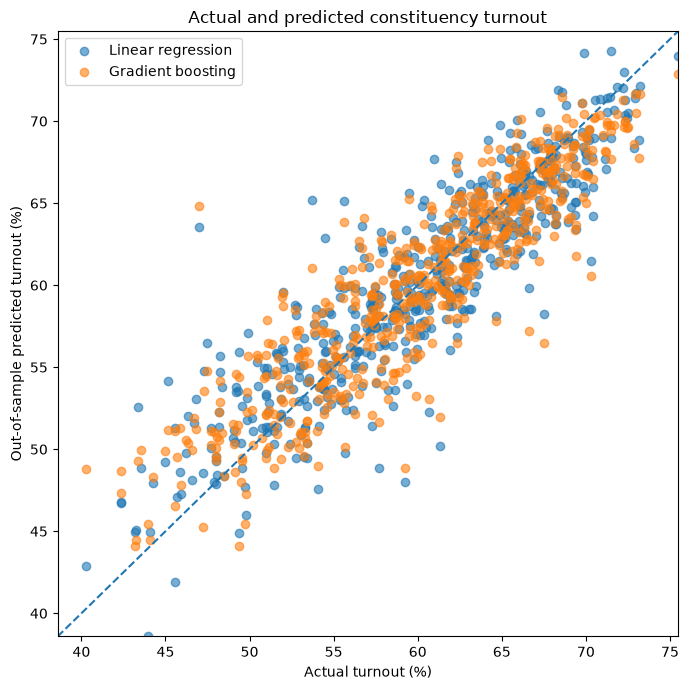

In [34]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    prediction_data["turnout_pct"],
    prediction_data["linear_predicted"],
    alpha=0.6,
    label="Linear regression"
)

ax.scatter(
    prediction_data["turnout_pct"],
    prediction_data["gb_predicted"],
    alpha=0.6,
    label="Gradient boosting"
)

limits = [
    min(
        prediction_data["turnout_pct"].min(),
        prediction_data["linear_predicted"].min(),
        prediction_data["gb_predicted"].min()
    ),
    max(
        prediction_data["turnout_pct"].max(),
        prediction_data["linear_predicted"].max(),
        prediction_data["gb_predicted"].max()
    )
]

ax.plot(
    limits,
    limits,
    linestyle="--"
)

ax.set_xlim(limits)
ax.set_ylim(limits)

ax.set_xlabel("Actual turnout (%)")
ax.set_ylabel("Out-of-sample predicted turnout (%)")
ax.set_title("Actual and predicted constituency turnout")

ax.legend()

plt.tight_layout()

plt.savefig(
    "../figures/actual_vs_predicted_turnout.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Where do the models get turnout wrong?

Looking at the constituency-level predictions shows that the largest errors are not random.

Several of the constituencies that are difficult to predict had unusual political circumstances in 2024. Chorley is the clearest example: both models predict turnout more than 16 percentage points above its actual level. Other large errors include Islington North, Leicester South, Leicester East and Brighton Pavilion, all of which had electoral contests that were unusual in ways not captured by the demographic variables used here.

This points to an important limit of the models. Constituency demographics explain a large share of the variation in turnout, but they cannot capture candidate effects, local campaigns or unusual patterns of party competition. The remaining prediction errors therefore seem to contain genuinely political information rather than simply showing that a more complicated demographic model is needed.

Gradient boosting improves overall prediction slightly, but it does not solve this problem. In some of the most unusual constituencies it performs no better than the linear model, and in the case of Chorley it performs worse.

In [35]:
prediction_data["gb_improvement"] = (
    prediction_data["linear_abs_error"]
    - prediction_data["gb_abs_error"]
)

prediction_data.nlargest(
    10,
    "gb_improvement"
)[
    [
        "constituency_name",
        "turnout_pct",
        "linear_predicted",
        "gb_predicted",
        "gb_improvement"
    ]
]

,constituency_name,turnout_pct,linear_predicted,gb_predicted,gb_improvement
219,Hampstead and Highgate,60.962901,67.702763,61.093977,6.608786
110,Chelsea and Fulham,60.279350,64.815243,60.506932,4.308311
122,Cities of London and Westminster,53.724325,65.181650,61.066691,4.114959
106,Ceredigion Preseli,61.377989,66.173944,62.194347,3.979597
36,Birmingham Ladywood,43.948717,38.585872,45.413400,3.898163
264,Kensington and Bayswater,54.486068,62.876254,59.004779,3.871475
409,Richmond Park,69.908519,74.172924,70.436184,3.736741
502,Swindon South,61.923527,56.073191,59.431948,3.358757
46,Blaenau Gwent and Rhymney,43.388023,52.560261,49.271595,3.288665
152,Doncaster North,45.122493,54.174681,51.201098,2.973582


In [36]:
prediction_data.nsmallest(
    10,
    "gb_improvement"
)[
    [
        "constituency_name",
        "turnout_pct",
        "linear_predicted",
        "gb_predicted",
        "gb_improvement"
    ]
]

,constituency_name,turnout_pct,linear_predicted,gb_predicted,gb_improvement
308,Manchester Rusholme,40.251763,42.908967,48.822635,-5.913668
397,Putney,68.119033,67.234455,62.975578,-4.258878
398,Queen's Park and Maida Vale,51.110405,52.295480,56.453802,-4.158322
286,Lewisham North,59.873324,57.015693,53.232812,-3.782882
287,Lewisham West and East Dulwich,67.199435,65.213813,61.498753,-3.715061
78,Bristol South,57.699284,58.102627,61.377219,-3.274593
291,Liverpool Garston,60.835426,59.671661,56.489079,-3.182582
65,Brent West,51.951216,56.185914,59.283496,-3.097582
61,Bradford West,47.883744,48.018076,51.030132,-3.012056
563,Wolverhampton West,56.274165,55.117985,52.139599,-2.978386


#### Out-of-sample predictions

Both models reproduce the broad pattern of turnout fairly well, although their predictions become less accurate at the extremes. Constituencies with very low turnout tend to be overpredicted, while those with very high turnout tend to be underpredicted.

Gradient boosting improves several of the linear model's larger errors, but this is not universal. In some constituencies it moves the prediction further away from the observed result. This helps explain why its average performance is slightly better without consistently beating the linear model in every cross-validation fold.

The largest remaining errors also suggest that demographic and socioeconomic variables are only part of the story. A model based on these characteristics can capture the broad differences between constituencies, but it is less able to deal with seats whose turnout is unusually high or low relative to their demographic profile.

### 5. Current summary

The demographic and socioeconomic variables used in this project are able to predict constituency turnout reasonably well out of sample. Ordinary least squares achieves an average cross-validation RMSE of around 3.1 percentage points and explains roughly 79% of the variation in turnout in held-out constituencies.

Regularisation does little to improve this. Ridge and LASSO perform almost identically to ordinary least squares, suggesting that the multicollinearity identified in NB04 matters more for coefficient interpretation than for prediction. LASSO nevertheless provides further evidence that the 18–34 age measure adds little unique information, setting its coefficient to zero in most of the fitted models.

Allowing for nonlinearities and interactions also produces only modest gains. Random forest performs slightly worse than the linear models, while gradient boosting gives the best average performance, reducing RMSE to around 3.05 percentage points. Its advantage is small, however, and it beats ordinary least squares in only half of the cross-validation folds.

Permutation importance shows that educational attainment and unemployment carry most of the predictive information, followed by social renting. Age and population density add relatively little unique predictive information once the other variables are included.

Overall, the results suggest that most of the relationship between constituency characteristics and turnout can be captured by a relatively simple linear model. More flexible machine-learning methods can make small improvements, but they do not fundamentally change the picture. The largest remaining prediction errors are more likely to reflect information missing from the model than a failure to use a sufficiently complicated algorithm.

In [37]:
model_comparison.to_csv(
    "../tables/predictive_model_comparison.csv"
)

prediction_data.to_csv(
    "../tables/out_of_sample_predictions.csv",
    index=False
)

### 6. Error analysis

Gradient boosting gives the best average predictive performance, but its errors are not equally distributed across constituencies.

I therefore look at whether the constituencies it predicts poorly share common characteristics. If large errors are concentrated among particular types of seat, this may point towards information missing from the current predictor set rather than simply random prediction noise.

In [38]:
error_analysis = data[
    ["constituency_name"] + predictive_features
].copy()

error_analysis["gb_error"] = prediction_data["gb_error"].values
error_analysis["gb_abs_error"] = prediction_data["gb_abs_error"].values

In [39]:
error_threshold = error_analysis["gb_abs_error"].quantile(0.90)

error_analysis["high_error"] = (
    error_analysis["gb_abs_error"] >= error_threshold
)

error_analysis["high_error"].value_counts()

high_error
False    517
True      58
Name: count, dtype: int64

In [40]:
standardised_features = (
    data[predictive_features]
    - data[predictive_features].mean()
) / data[predictive_features].std()

standardised_features["high_error"] = (
    error_analysis["high_error"].values
)

high_error_profile = (
    standardised_features
    .groupby("high_error")
    .mean()
    .T
)

high_error_profile.columns = [
    "Other constituencies",
    "Worst-predicted 10%"
]

high_error_profile["difference"] = (
    high_error_profile["Worst-predicted 10%"]
    - high_error_profile["Other constituencies"]
)

high_error_profile.sort_values(
    "difference",
    key=abs,
    ascending=False
)

,Other constituencies,Worst-predicted 10%,difference
age_18_34_pct,-0.080303,0.715806,0.796109
owner_occupied_pct,0.080218,-0.715047,-0.795265
unemployment_rate,-0.074928,0.667889,0.742817
age_65_plus_pct,0.074773,-0.666508,-0.741280
social_rented_pct,-0.062852,0.560248,0.623100
log_population_density,-0.052628,0.469115,0.521743
level4_plus_pct,-0.020472,0.182481,0.202952


In [41]:
error_correlations = (
    error_analysis[
        predictive_features + ["gb_error"]
    ]
    .corr()["gb_error"]
    .drop("gb_error")
    .sort_values(key=abs, ascending=False)
)

error_correlations

level4_plus_pct           0.084553
age_65_plus_pct           0.054786
age_18_34_pct            -0.047403
owner_occupied_pct        0.047251
unemployment_rate        -0.043220
social_rented_pct        -0.026019
log_population_density   -0.013051
Name: gb_error, dtype: float64

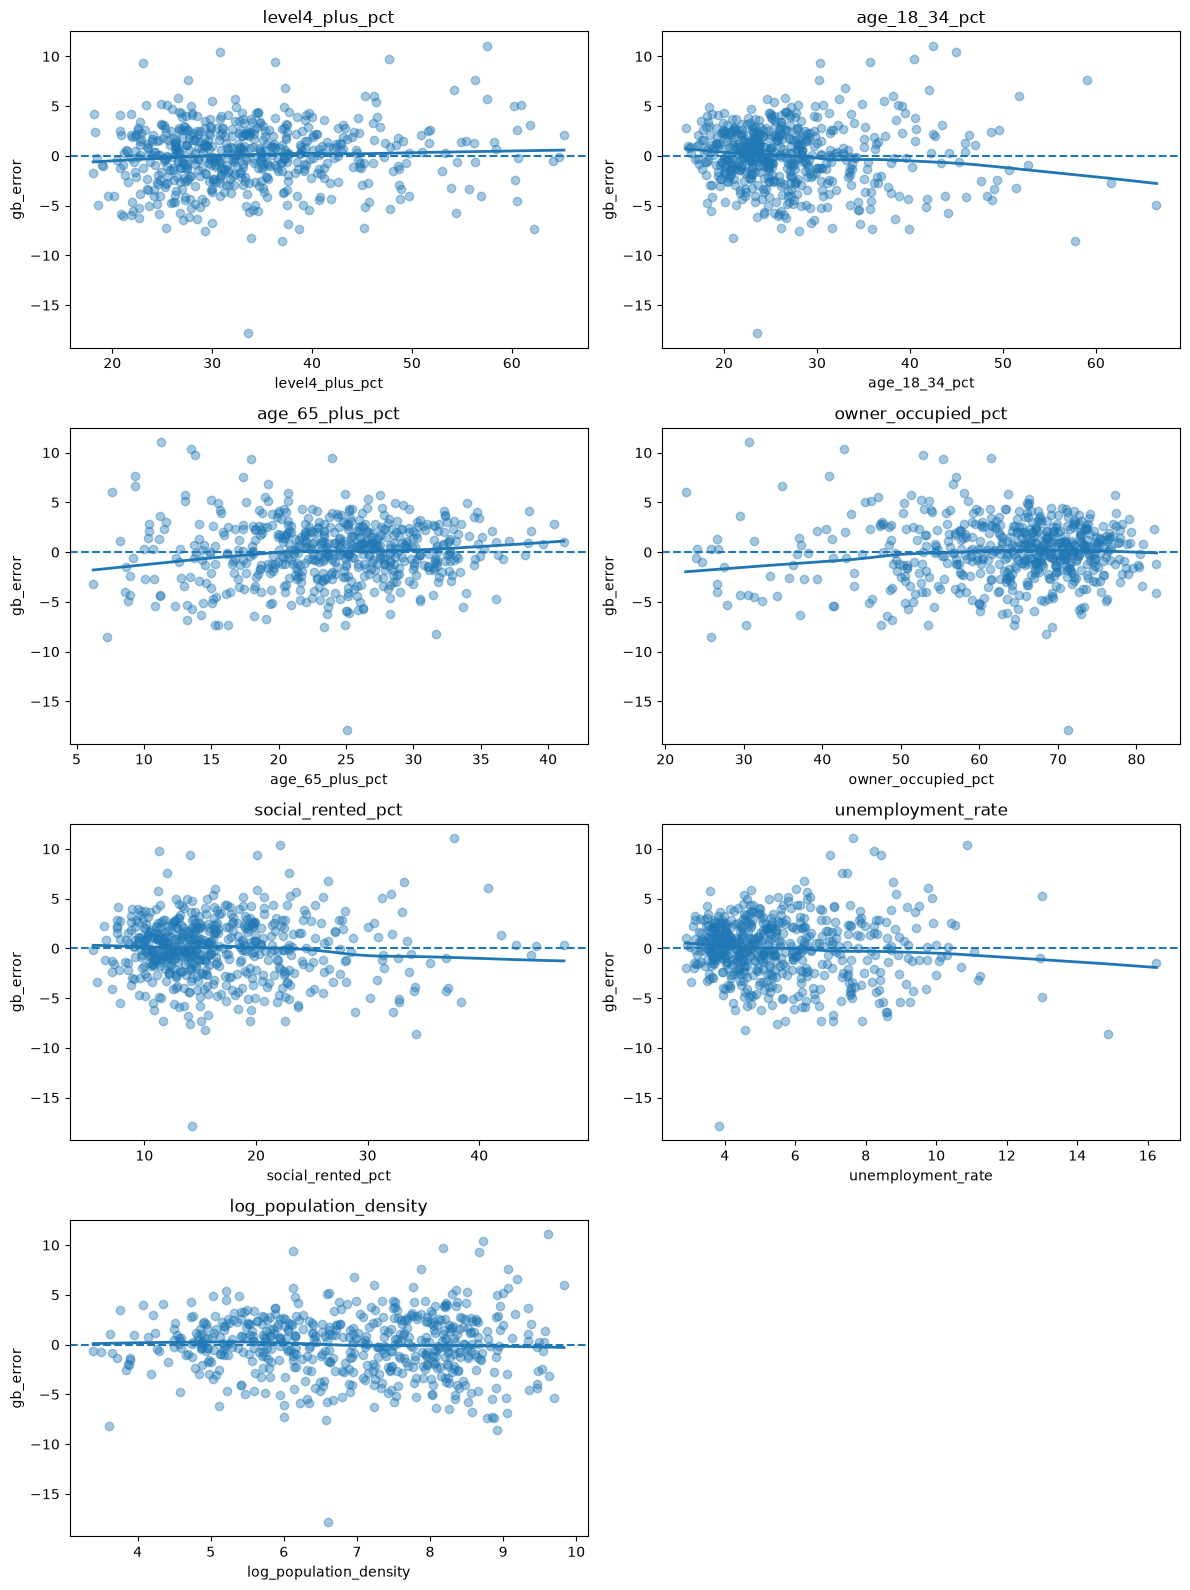

In [42]:
fig, axes = plt.subplots(
    4,
    2,
    figsize=(12, 16)
)

axes = axes.flatten()

for ax, predictor in zip(
    axes,
    predictive_features
):
    sns.regplot(
        data=error_analysis,
        x=predictor,
        y="gb_error",
        lowess=True,
        scatter_kws={"alpha": 0.4},
        line_kws={"linewidth": 2},
        ax=ax
    )

    ax.axhline(0, linestyle="--")
    ax.set_title(predictor)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [43]:
[
    column
    for column in data.columns
    if (
        "region" in column.lower()
        or "country" in column.lower()
    )
]

['region_name', 'country_name']

In [44]:
regional_errors = (
    prediction_data
    .merge(
        data[
            [
                "constituency_code",
                "region_name"   # replace with actual column name
            ]
        ],
        on="constituency_code"
    )
    .groupby("region_name")
    .agg(
        mean_error=("gb_error", "mean"),
        mean_abs_error=("gb_abs_error", "mean"),
        n=("constituency_code", "size")
    )
    .sort_values("mean_abs_error", ascending=False)
)

regional_errors

,mean_error,mean_abs_error,n
region_name,,,
Wales,-3.374889,3.410741,32
Yorkshire and The Humber,-2.308407,2.846411,54
London,0.076688,2.677384,75
North West,-1.777781,2.595400,73
South West,1.463377,2.225110,58
East of England,0.902014,2.180853,61
South East,1.382445,2.100383,91
North East,1.257733,1.929774,27
East Midlands,0.862947,1.771905,47


#### Patterns in the remaining errors

The largest prediction errors are concentrated disproportionately among younger, denser and more economically disadvantaged constituencies. However, these characteristics are themselves strongly correlated, and the signed prediction errors have only weak relationships with the individual predictors.

Geography shows a clearer pattern. The model systematically overpredicts turnout in Wales, Yorkshire and the Humber and the North West, while tending to underpredict turnout in parts of southern England. This suggests that the existing demographic variables do not fully capture regional differences in turnout.

Region is therefore a reasonable additional predictor to test. Unlike measures derived from the 2024 election result, it is known in advance and does not introduce information from the outcome being predicted.

### 7. Regional Effects

In [45]:
numeric_features = predictive_features
categorical_features = ["region_name"]

X_region = data[
    numeric_features + categorical_features
]

In [46]:
region_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features
        ),
        (
            "region",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [47]:
linear_region_model = Pipeline([
    ("preprocessor", region_preprocessor),
    ("model", LinearRegression())
])

linear_region_scores = cross_validate(
    linear_region_model,
    X_region,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

linear_region_results = pd.Series({
    "RMSE": -linear_region_scores["test_rmse"].mean(),
    "MAE": -linear_region_scores["test_mae"].mean(),
    "R²": linear_region_scores["test_r2"].mean()
})

linear_region_results

RMSE    2.473201
MAE     1.907532
R²      0.867044
dtype: float64

In [48]:
gb_region_pipeline = Pipeline([
    ("preprocessor", region_preprocessor),
    (
        "model",
        GradientBoostingRegressor(
            random_state=42
        )
    )
])

In [49]:
gb_region_search = RandomizedSearchCV(
    estimator=gb_region_pipeline,
    param_distributions={
        "model__n_estimators": [50, 100, 150, 200, 300],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.075, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [2, 4, 8, 12],
        "model__subsample": [0.7, 0.85, 1.0]
    },
    n_iter=12,
    cv=inner_cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1
)

gb_region_scores = cross_validate(
    gb_region_search,
    X_region,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

gb_region_results = pd.Series({
    "RMSE": -gb_region_scores["test_rmse"].mean(),
    "MAE": -gb_region_scores["test_mae"].mean(),
    "R²": gb_region_scores["test_r2"].mean()
})

gb_region_results

RMSE    2.755467
MAE     2.106379
R²      0.833474
dtype: float64

In [50]:
regional_model_comparison = pd.DataFrame({
    "OLS": linear_results,
    "OLS + region": linear_region_results,
    "Gradient boosting": gb_results,
    "Gradient boosting + region": gb_region_results
}).T

regional_model_comparison

,RMSE,MAE,R²
OLS,3.093503,2.358713,0.793275
OLS + region,2.473201,1.907532,0.867044
Gradient boosting,3.049720,2.348461,0.796730
Gradient boosting + region,2.755467,2.106379,0.833474


#### Adding regional information

The error analysis suggested that the original models were missing a strong geographical pattern. Turnout was systematically overpredicted in Wales, Yorkshire and the Humber and the North West, while it was generally underpredicted in southern England.

Adding region as a predictor produces a much larger improvement than changing the modelling algorithm. The cross-validated RMSE of the linear model falls from 3.09 to 2.47pp, while out-of-sample R^2 from around 0.79 to 0.87.

Perhaps more importantly, the regional linear model also outperforms gradient boosting with the same additional information. This suggests that much of the structure missed by the original model is not particularly complex or nonlinear. Instead, constituencies appear to have systematic regional differences in turnout that are not fully captured by the demographic and socioeconomic variables.

The result also changes the interpretation of the earlier machine-learning comparison. Gradient boosting was able to recover a small amount of additional predictive information from the original variables, but this gain was minor compared with simply adding a substantively relevant piece of information that the model had previously omitted.

In [51]:
regional_fold_comparison = pd.DataFrame({
    "OLS": -linear_scores["test_rmse"],
    "OLS + region": -linear_region_scores["test_rmse"],
    "GB + region": -gb_region_scores["test_rmse"]
})

regional_differences = pd.DataFrame({
    "OLS + region minus OLS": (
        -linear_region_scores["test_rmse"]
        + linear_scores["test_rmse"]
    ),
    "GB + region minus OLS + region": (
        -gb_region_scores["test_rmse"]
        + linear_region_scores["test_rmse"]
    )
})

regional_differences.describe()

,OLS + region minus OLS,GB + region minus OLS + region
count,50.000000,50.000000
mean,-0.620302,0.282266
std,0.168496,0.244329
min,-0.984128,-0.389081
25%,-0.739533,0.148709
50%,-0.602113,0.280729
75%,-0.502314,0.389233
max,-0.271084,0.827078


In [52]:
print(
    "OLS + region beats OLS in",
    (regional_differences["OLS + region minus OLS"] < 0).sum(),
    "of 50 folds"
)

print(
    "OLS + region beats GB + region in",
    (regional_differences["GB + region minus OLS + region"] > 0).sum(),
    "of 50 folds"
)

OLS + region beats OLS in 50 of 50 folds
OLS + region beats GB + region in 44 of 50 folds


In [53]:
linear_region_model.fit(X_region, y)

feature_names = (
    linear_region_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

region_coefficients = pd.Series(
    linear_region_model.named_steps["model"].coef_,
    index=feature_names
)

region_coefficients[
    region_coefficients.index.str.startswith("region__")
].sort_values()

region__region_name_Wales                      -4.477309
region__region_name_Yorkshire and The Humber   -2.139319
region__region_name_North West                 -1.565259
region__region_name_London                     -0.209656
region__region_name_West Midlands              -0.205031
region__region_name_North East                 -0.016776
region__region_name_East of England             1.742045
region__region_name_East Midlands               1.784337
region__region_name_South East                  2.211851
region__region_name_South West                  2.875115
dtype: float64

In [54]:
interpretation_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        (
            "region",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

interpretation_model = Pipeline([
    ("preprocessor", interpretation_preprocessor),
    ("model", LinearRegression())
])

interpretation_model.fit(X_region, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['level4_plus_pct','age_18_34_pct','age_65_plus_pct',..., 'unemployment_rate','log_population_density','region_name']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('region', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be a

In [55]:
feature_names = (
    interpretation_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = pd.Series(
    interpretation_model.named_steps["model"].coef_,
    index=feature_names
)

coefficients

numeric__level4_plus_pct                        0.507982
numeric__age_18_34_pct                          0.032438
numeric__age_65_plus_pct                        0.229949
numeric__owner_occupied_pct                     0.246069
numeric__social_rented_pct                     -0.029218
numeric__unemployment_rate                     -0.305899
numeric__log_population_density                -0.526085
region__region_name_East of England            -0.042292
region__region_name_London                     -1.993993
region__region_name_North East                 -1.801113
region__region_name_North West                 -3.349596
region__region_name_South East                  0.427513
region__region_name_South West                  1.090778
region__region_name_Wales                      -6.261646
region__region_name_West Midlands              -1.989368
region__region_name_Yorkshire and The Humber   -3.923657
dtype: float64

In [56]:
interpretation_model.named_steps[
    "preprocessor"
].named_transformers_["region"].categories_

[array(['East Midlands', 'East of England', 'London', 'North East',
        'North West', 'South East', 'South West', 'Wales', 'West Midlands',
        'Yorkshire and The Humber'], dtype=object)]

The improvement from adding region is not confined to a small number of cross-validation splits. The regional linear model outperforms the original linear model in all 50 folds, reducing RMSE by around 0.62pp on average. It also outperforms gradient boosting with the same regional information in 44 of the 50 folds.

This makes the source of the earlier prediction errors much clearer. The main problem was not that the relationship between the existing predictors and turnout was too complex for a linear model. Instead, there are substantial regional differences in turnout that are not fully captured by the demographic and socioeconomic variables.

Using East Midlands as the reference category, the fitted model predicts particularly lower turnout in Wales, Yorkshire and the Humber and the North West, even after controlling for the other constituency characteristics. Southern regions tend to sit above the East Midlands baseline.

Adding region also changes some of the other coefficients. In particular, the estimated relationship with unemployment becomes much smaller, while the social renting coefficient falls close to zero. This suggests that part of the association previously attributed to deprivation was capturing broader regional differences. Educational attainment remains strongly associated with turnout after region is included.

In [57]:
region_prediction_sum = np.zeros(len(data))
prediction_count = np.zeros(len(data))

for train_idx, test_idx in cv.split(X_region, y):
    fold_model = Pipeline([
        ("preprocessor", region_preprocessor),
        ("model", LinearRegression())
    ])

    fold_model.fit(
        X_region.iloc[train_idx],
        y.iloc[train_idx]
    )

    fold_predictions = fold_model.predict(
        X_region.iloc[test_idx]
    )

    region_prediction_sum[test_idx] += fold_predictions
    prediction_count[test_idx] += 1

assert (prediction_count == 5).all()

region_oof = (
    region_prediction_sum
    / prediction_count
)

In [58]:
prediction_data["region_linear_predicted"] = region_oof

prediction_data["region_linear_error"] = (
    prediction_data["turnout_pct"]
    - prediction_data["region_linear_predicted"]
)

prediction_data["region_linear_abs_error"] = (
    prediction_data["region_linear_error"].abs()
)

In [59]:
region_oof_results = pd.Series({
    "RMSE": root_mean_squared_error(
        y,
        region_oof
    ),
    "MAE": mean_absolute_error(
        y,
        region_oof
    ),
    "R²": r2_score(
        y,
        region_oof
    )
})

region_oof_results

RMSE    2.495037
MAE     1.905188
R²      0.873111
dtype: float64

In [60]:
regional_residual_check = (
    prediction_data
    .merge(
        data[
            [
                "constituency_code",
                "region_name"
            ]
        ],
        on="constituency_code"
    )
    .groupby("region_name")
    .agg(
        mean_error=(
            "region_linear_error",
            "mean"
        ),
        mean_abs_error=(
            "region_linear_abs_error",
            "mean"
        ),
        n=(
            "constituency_code",
            "size"
        )
    )
    .sort_values(
        "mean_abs_error",
        ascending=False
    )
)

regional_residual_check

,mean_error,mean_abs_error,n
region_name,,,
London,0.003886,2.406695,75
North West,-0.025243,2.144348,73
Wales,-0.005265,2.080095,32
North East,-0.028932,1.986595,27
East Midlands,-0.016138,1.937242,47
East of England,-0.001759,1.863041,61
West Midlands,-0.004387,1.816779,57
Yorkshire and The Humber,-0.006488,1.775233,54
South East,-0.001293,1.599577,91


In [61]:
prediction_data.nlargest(
    15,
    "region_linear_abs_error"
)[
    [
        "constituency_name",
        "turnout_pct",
        "region_linear_predicted",
        "region_linear_error"
    ]
]

,constituency_name,turnout_pct,region_linear_predicted,region_linear_error
120,Chorley,47.007393,61.578802,-14.571409
280,Leicester East,61.349269,51.333258,10.016010
122,Cities of London and Westminster,53.724325,63.461625,-9.737300
259,Islington North,67.527316,58.386274,9.141041
281,Leicester South,59.258893,50.307601,8.951292
26,Bethnal Green and Stepney,57.671386,49.378336,8.293050
264,Kensington and Bayswater,54.486068,61.904886,-7.418817
152,Doncaster North,45.122493,52.238412,-7.115919
73,Brighton Pavilion,70.296580,63.314903,6.981676
381,Oxford East,55.300995,61.263740,-5.962745


### Error analysis of the regional model

Adding region removes the systematic geographical bias in the original models. The remaining errors can therefore be used to ask whether another common type of constituency is still being predicted badly, or whether the largest misses are mostly seat-specific.

In [62]:
region_error_analysis = data[
    ["constituency_name"] + predictive_features
].copy()

region_error_analysis["error"] = (
    prediction_data["region_linear_error"].values
)

region_error_analysis["abs_error"] = (
    prediction_data["region_linear_abs_error"].values
)

error_threshold = (
    region_error_analysis["abs_error"]
    .quantile(0.90)
)

region_error_analysis["high_error"] = (
    region_error_analysis["abs_error"]
    >= error_threshold
)

region_error_analysis["high_error"].value_counts()

high_error
False    517
True      58
Name: count, dtype: int64

In [63]:
standardised_features = (
    data[predictive_features]
    - data[predictive_features].mean()
) / data[predictive_features].std()

standardised_features["high_error"] = (
    region_error_analysis["high_error"].values
)

region_high_error_profile = (
    standardised_features
    .groupby("high_error")
    .mean()
    .T
)

region_high_error_profile.columns = [
    "Other constituencies",
    "Worst-predicted 10%"
]

region_high_error_profile["difference"] = (
    region_high_error_profile["Worst-predicted 10%"]
    - region_high_error_profile["Other constituencies"]
)

region_high_error_profile.sort_values(
    "difference",
    key=abs,
    ascending=False
)

,Other constituencies,Worst-predicted 10%,difference
age_18_34_pct,-0.075217,0.670467,0.745684
owner_occupied_pct,0.074698,-0.665845,-0.740543
age_65_plus_pct,0.071336,-0.635879,-0.707215
social_rented_pct,-0.058173,0.518541,0.576714
unemployment_rate,-0.057293,0.510694,0.567986
log_population_density,-0.057043,0.508470,0.565513
level4_plus_pct,-0.018553,0.165376,0.183929


In [64]:
region_error_correlations = (
    region_error_analysis[
        predictive_features + ["error"]
    ]
    .corr()["error"]
    .drop("error")
    .sort_values(
        key=abs,
        ascending=False
    )
)

region_error_correlations

owner_occupied_pct        0.002253
social_rented_pct        -0.001712
unemployment_rate        -0.001501
age_18_34_pct            -0.001273
age_65_plus_pct          -0.000642
level4_plus_pct           0.000506
log_population_density   -0.000015
Name: error, dtype: float64

In [65]:
high_error_by_region = (
    pd.DataFrame({
        "region_name": data["region_name"],
        "high_error": region_error_analysis["high_error"]
    })
    .groupby("region_name")
    .agg(
        high_error_count=("high_error", "sum"),
        n=("high_error", "size")
    )
)

high_error_by_region["high_error_share"] = (
    high_error_by_region["high_error_count"]
    / high_error_by_region["n"]
)

high_error_by_region.sort_values(
    "high_error_share",
    ascending=False
)

,high_error_count,n,high_error_share
region_name,,,
North East,4,27,0.148148
London,11,75,0.146667
East of England,8,61,0.131148
Wales,4,32,0.125000
North West,7,73,0.095890
South East,8,91,0.087912
East Midlands,4,47,0.085106
Yorkshire and The Humber,4,54,0.074074
West Midlands,4,57,0.070175


#### Remaining prediction errors

Adding region removes the systematic geographical bias in the original model.Mean prediction errors are now close to zero in every region, and the signedresiduals have virtually no remaining correlation with any of the existing predictors.

The largest errors are nevertheless concentrated among a recognisable type of constituency. The worst-predicted 10% are substantially younger, less owner-occupied, more densely populated and more likely to have higher levels of social renting and unemployment.

This does not mean the model consistently predicts turnout too high or too low in these constituencies. Instead, turnout appears to be more variable among younger and more urban seats in ways that the current predictors do not explain. This points towards missing information rather than another simple transformation of the variables already in the model.

### 8. Student Status Analysis

In [66]:
data[
    [
        "constituency_name",
        "student_pct"
    ]
].nlargest(
    15,
    "student_pct"
)

,constituency_name,student_pct
273,Leeds Central and Headingley,43.789864
431,Sheffield Central,38.568265
308,Manchester Rusholme,34.741345
374,Nottingham South,32.820150
74,Bristol Central,30.183574
292,Liverpool Riverside,27.886691
94,Cambridge,27.112178
372,Nottingham East,25.657260
134,Coventry South,25.595034
99,Cardiff South and Penarth,24.358548


In [67]:
numeric_features_student = predictive_features + ["student_pct"]

X_region_student = data[
    numeric_features_student + ["region_name"]
]

student_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features_student
        ),
        (
            "region",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            ["region_name"]
        )
    ]
)

linear_region_student_model = Pipeline([
    ("preprocessor", student_preprocessor),
    ("model", LinearRegression())
])

In [68]:
linear_region_student_scores = cross_validate(
    linear_region_student_model,
    X_region_student,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

linear_region_student_results = pd.Series({
    "RMSE": -linear_region_student_scores["test_rmse"].mean(),
    "MAE": -linear_region_student_scores["test_mae"].mean(),
    "R²": linear_region_student_scores["test_r2"].mean()
})

linear_region_student_results

RMSE    2.475761
MAE     1.904110
R²      0.866579
dtype: float64

In [69]:
student_model_comparison = pd.DataFrame({
    "OLS + region": linear_region_results,
    "OLS + region + student share": linear_region_student_results
}).T

student_model_comparison

,RMSE,MAE,R²
OLS + region,2.473201,1.907532,0.867044
OLS + region + student share,2.475761,1.904110,0.866579


In [70]:
student_rmse_difference = (
    -linear_region_student_scores["test_rmse"]
    + linear_region_scores["test_rmse"]
)

pd.Series(student_rmse_difference).describe()

count    50.000000
mean      0.002560
std       0.024246
min      -0.024829
25%      -0.014212
50%      -0.004125
75%       0.009897
max       0.069686
dtype: float64

In [71]:
print(
    "Student model beats regional OLS in",
    (student_rmse_difference < 0).sum(),
    "of 50 folds"
)

Student model beats regional OLS in 33 of 50 folds


In [72]:
data[
    ["student_pct", "age_18_34_pct"]
].corr()

,student_pct,age_18_34_pct
student_pct,1.000000,0.845225
age_18_34_pct,0.845225,1.000000


In [73]:
pd.Series(
    student_rmse_difference,
    name="Student minus regional OLS RMSE"
).describe()

count    50.000000
mean      0.002560
std       0.024246
min      -0.024829
25%      -0.014212
50%      -0.004125
75%       0.009897
max       0.069686
Name: Student minus regional OLS RMSE, dtype: float64

In [74]:
print(
    "Mean difference:",
    student_rmse_difference.mean()
)

print(
    "Median difference:",
    np.median(student_rmse_difference)
)

print(
    "Best improvement:",
    student_rmse_difference.min()
)

print(
    "Worst deterioration:",
    student_rmse_difference.max()
)

Mean difference: 0.0025600782963318292
Median difference: -0.004125036484451838
Best improvement: -0.02482901057392306
Worst deterioration: 0.06968637766857677


#### Testing student population

The remaining large prediction errors are concentrated disproportionately among younger and more urban constituencies, including several seats with large student populations. I therefore test whether student population provides information that is missing from the regional model.

Student share is strongly correlated with the existing 18–34 population measure (r = 0.85). Adding it produces almost no change in overall predictive performance. The student model has a lower RMSE in 33 of the 50 cross-validation folds, but these improvements are generally very small. Its mean RMSE is actually around
0.003pp higher than the simpler regional model.

The distribution of the fold-level differences helps explain this result. The median difference slightly favours the student model, but its occasional deteriorations are larger than its best improvements. Student population therefore appears to identify a genuine characteristic of many difficult-to-predict seats, without contributing enough new information to improve prediction overall.

I therefore retain the model with the original Census predictors and region as the preferred predictive specification.

In [75]:
final_model_comparison = pd.DataFrame({
    "OLS": linear_results,
    "Ridge": ridge_results,
    "LASSO": lasso_results,
    "Random forest": rf_results,
    "Gradient boosting": gb_results,
    "OLS + region": linear_region_results,
    "Gradient boosting + region": gb_region_results,
    "OLS + region + student share": linear_region_student_results
}).T

final_model_comparison.sort_values("RMSE")

,RMSE,MAE,R²
OLS + region,2.473201,1.907532,0.867044
OLS + region + student share,2.475761,1.904110,0.866579
Gradient boosting + region,2.755467,2.106379,0.833474
Gradient boosting,3.049720,2.348461,0.796730
LASSO,3.091682,2.361250,0.793572
OLS,3.093503,2.358713,0.793275
Ridge,3.093825,2.361266,0.793291
Random forest,3.144900,2.418537,0.784820


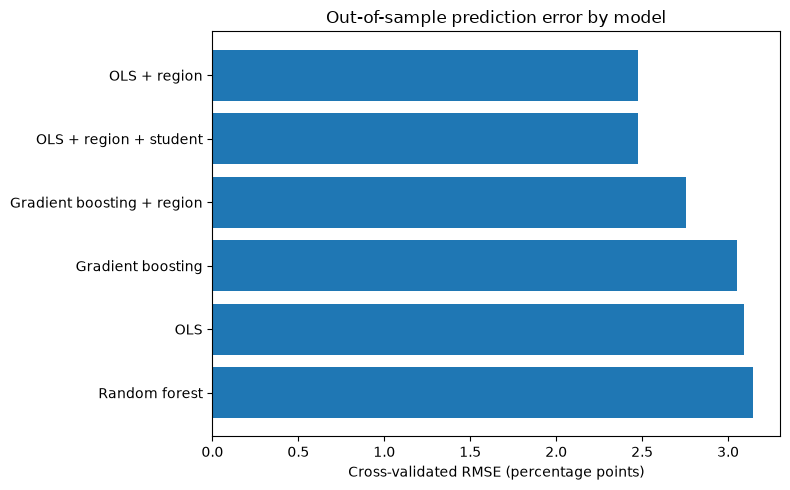

In [76]:
final_plot_data = pd.DataFrame({
    "Model": [
        "OLS",
        "Random forest",
        "Gradient boosting",
        "Gradient boosting + region",
        "OLS + region",
        "OLS + region + student"
    ],
    "RMSE": [
        linear_results["RMSE"],
        rf_results["RMSE"],
        gb_results["RMSE"],
        gb_region_results["RMSE"],
        linear_region_results["RMSE"],
        linear_region_student_results["RMSE"]
    ]
}).sort_values("RMSE", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    final_plot_data["Model"],
    final_plot_data["RMSE"]
)

ax.set_xlabel("Cross-validated RMSE (percentage points)")
ax.set_title("Out-of-sample prediction error by model")

plt.tight_layout()

plt.savefig(
    "../figures/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

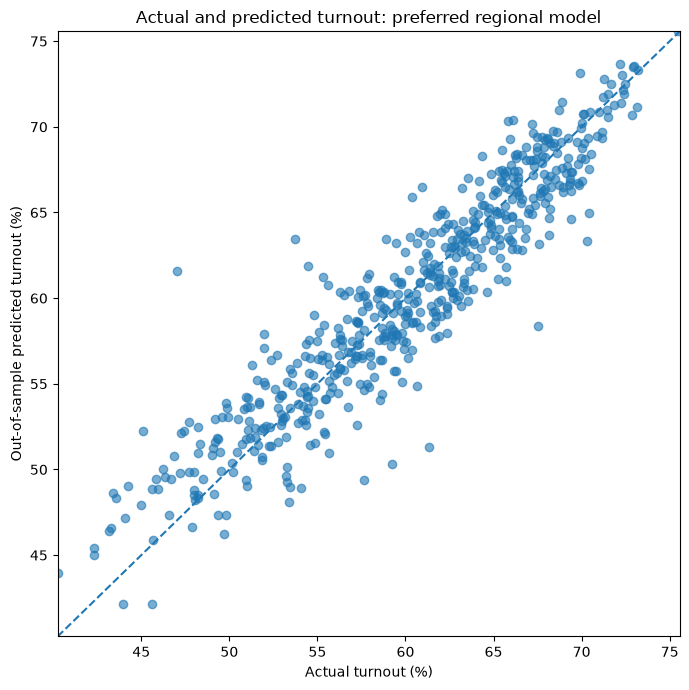

In [77]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    prediction_data["turnout_pct"],
    prediction_data["region_linear_predicted"],
    alpha=0.6
)

limits = [
    min(
        prediction_data["turnout_pct"].min(),
        prediction_data["region_linear_predicted"].min()
    ),
    max(
        prediction_data["turnout_pct"].max(),
        prediction_data["region_linear_predicted"].max()
    )
]

ax.plot(
    limits,
    limits,
    linestyle="--"
)

ax.set_xlim(limits)
ax.set_ylim(limits)

ax.set_xlabel("Actual turnout (%)")
ax.set_ylabel("Out-of-sample predicted turnout (%)")
ax.set_title("Actual and predicted turnout: preferred regional model")

plt.tight_layout()

plt.savefig(
    "../figures/preferred_model_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9. Final Predictive modelling summary

The initial demographic model predicts constituency turnout reasonably well out of sample. Ordinary least squares achieves an average cross-validation RMSE of 3.09pp and an R^2nd 0.79. Regularisation changes very little: Ridge and LASSO perform almost identically to OLS, while LASSO frequently removes the 18–34 population measure. This supports the earlier conclusion that multicollinearity creates more difficulty for coefficient interpretation than for prediction.

More flexible machine-learning models also offer little improvement when given the same information. Gradient boosting performs slightly better than the original linear model, but the reduction in RMSE is only around 0.04pp and is not consistent across cross-validation folds. Random forest performs slightly worse.

The more important result comes from examining where these models fail. Their prediction errors show a clear regional pattern: turnout is systematically overpredicted in Wales, Yorkshire and the Humber and the North West, while it is underpredicted in parts of southern England. Adding region to the linear model reduces average cross-validation RMSE from 3.09 to 2.47 and raises out-of-sample R^2 from around 0.79 to 0.87. The improvement occurs in all 50 cross-validation folds.

Once region is included, the geographical bias in the residuals almost completely disappears. Gradient boosting with the same regional information still performs worse than the regional linear model, suggesting that the main problem with the original specification was omitted geographical structure rather than insufficient model complexity.

Region was added after systematic geographical patterns were identified in the out-of-sample residuals, rather than being specified in advance. The improvement should therefore be treated as an exploratory model-development result rather than evidence from a completely untouched validation sample. All reported model comparisons still evaluate individual constituencies out of sample within the cross-validation procedure.

The remaining large errors are concentrated disproportionately among younger, denser and less owner-occupied constituencies. Student population was tested as one possible explanation for this pattern. Although student share identifies many of these seats and improves prediction slightly in a majority of folds, it is strongly correlated with the existing 18–34 measure and does not improve average RMSE. I therefore retain the simpler regional linear model as the preferred predictive specification.

Overall, the exercise suggests that additional relevant information matters more for predicting turnout than additional algorithmic complexity. A relatively simple linear model performs best once an important source of geographical variation is included. The remaining large errors are increasingly constituency-specific and are likely to reflect political or local factors that are not represented in the Census predictors.



In [78]:
final_model_comparison.to_csv(
    "../tables/predictive_model_comparison.csv"
)

In [79]:
prediction_data.to_csv(
    "../tables/out_of_sample_predictions.csv",
    index=False
)